# ResNet18 experiments: transfer learning after our CNN baselines

**Question:** does adapting a network pretrained on other images improve our 12-class thermal solar-module classifier?

This notebook explains and reviews **existing repository experiments**: frozen ResNet18 → fine-tune its last residual stage → test augmentation → choose learning rates with training-only cross-validation. It compares their recorded validation results with the newer optimised SmallCNN references. It does not launch training when run from top to bottom.

The older ResNet experiments predate our latest SmallCNN tuning; this is a teaching sequence, not a claim that they were run afterwards. Reported historical values are labelled as such. The original test set remains reserved.

In [1]:
from pathlib import Path
import sys
import json
import hashlib
import inspect
import subprocess
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn

ROOT = Path.cwd().resolve()
if not (ROOT / "src/pv_fault").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src/pv_fault").is_dir():
    raise RuntimeError("Open this notebook from the repository root or notebooks folder.")
sys.path.insert(0, str(ROOT / "src"))
from pv_fault.data import CLASS_NAMES
from pv_fault.models.resnet import (
    ResNet18Thermal, enable_layer4_finetuning, preprocess_thermal,
    IMAGENET_MEAN, IMAGENET_STD, WEIGHT_SHA256,
)

SEED = 2112
PLAN_FILES = {
    "frozen": "experiment-plan-resnet18.json",
    "layer4": "experiment-plan-resnet18-finetune.json",
    "augmentation": "experiment-plan-resnet18-augmentation.json",
    "cv": "experiment-plan-resnet18-cv.json",
    "selected": "experiment-plan-resnet18-selected.json",
}
plans = {key: json.loads((ROOT / "configs" / filename).read_text())
         for key, filename in PLAN_FILES.items()}
manifest_path = ROOT / plans["frozen"]["manifest"]
manifest_sha = hashlib.sha256(manifest_path.read_bytes()).hexdigest()
assert all(p["manifest_sha256"] == manifest_sha for p in plans.values())
manifest = pd.read_csv(manifest_path)
display(manifest.groupby("split").size().rename("Images").to_frame())
print("Verified shared manifest checksum:", manifest_sha)
print("This checks the split file; full image verification is separate.")

,Images
split,
test,2988
train,13946
val,2988


Verified shared manifest checksum: 8c6c80cc05943e85d4a03874b1d5d89cb83eaf98e5637560b9ec9a2dcdee1ef8
This checks the split file; full image verification is separate.


## 1. Why try transfer learning?

SmallCNN and WideCNN start with random weights and learn all their features from our training images. ResNet18 starts with weights learned from ImageNet images. Its features may provide a useful starting point, even though natural colour photographs differ from thermal module crops. This benefit must be tested.

ResNet uses **residual connections**. A residual block combines its learned transformation with a shortcut: `output = ReLU(F(input) + shortcut(input))`. A projection shortcut adjusts shape when needed. These connections help gradients pass through a deeper network. The architecture name does not mean 18 output classes: we replace its classifier with **12 outputs**, matching our dataset.

The shared implementation lives in `src/pv_fault/models/resnet.py`. Training stays in the existing scripts; this notebook explains and inspects those implementations.

## 2. How our grayscale images enter ResNet

Our loader returns `[batch, 1, 40, 24]` values scaled to 0–1. The shared adapter:

1. Resizes each crop to **80 × 48** using bilinear interpolation, preserving its aspect ratio. This adds pixels, not new image detail.
2. Copies its single grayscale channel into three channels to match the pretrained network's input. This does not create colour information.
3. Subtracts ImageNet channel means and divides by ImageNet channel standard deviations. Values can now be negative or above 1. This is input normalisation, not a probability calculation.

The same deterministic adapter runs for training and evaluation. Our training-only augmentation experiment acts before this adapter.

In [2]:
mean = torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1)
std = torch.tensor(IMAGENET_STD).view(1, 3, 1, 1)
example = torch.full((1, 1, 40, 24), 0.5)  # synthetic image, not a data split
adapted = preprocess_thermal(example, mean, std)
print("Before adapter:", tuple(example.shape))
print("After adapter: ", tuple(adapted.shape))
display(pd.DataFrame({
    "Channel": ["R copy", "G copy", "B copy"],
    "Original brightness": [0.5] * 3,
    "ImageNet mean": IMAGENET_MEAN,
    "ImageNet std": IMAGENET_STD,
    "Normalised value": adapted[0, :, 0, 0].tolist(),
}).round(3))

Before adapter: (1, 1, 40, 24)
After adapter:  (1, 3, 80, 48)


,Channel,Original brightness,ImageNet mean,ImageNet std,Normalised value
0,R copy,0.5,0.485,0.229,0.066
1,G copy,0.5,0.456,0.224,0.196
2,B copy,0.5,0.406,0.225,0.418


## 3. First experiment: freeze the feature extractor

We keep the pretrained backbone fixed and replace its original classifier with `nn.Linear(512, 12)`. Only this new head learns. Its parameter count is **512 × 12 weights + 12 biases = 6,156**.

Freezing involves two different controls: `requires_grad=False` prevents weight updates, while keeping backbone BatchNorm layers in evaluation mode prevents their running statistics from changing. Our model's `train()` override does both parts needed for the frozen experiment; the classifier still enters training mode.

The plan uses Adam, learning rate 0.001, batch 64 and training-only square-root inverse-frequency class weights. The cap is five epochs, with checkpoint selection by unweighted validation macro-F1. These differ from the later CNN budgets, so this is a comparison of complete experiments, not an equal-compute architecture test.

In [3]:
# Show the actual shared code that controls freezing and the new classifier.
print(inspect.getsource(ResNet18Thermal.__init__))
print(inspect.getsource(ResNet18Thermal.train))
head = nn.Linear(512, len(CLASS_NAMES))
assert sum(p.numel() for p in head.parameters()) == 6156
print("Trainable head parameters:", sum(p.numel() for p in head.parameters()))

weight_path = ROOT / plans["frozen"]["pretrained_weights"]
if weight_path.is_file():
    assert hashlib.sha256(weight_path.read_bytes()).hexdigest() == WEIGHT_SHA256
    print("Local pretrained weights are present and checksum-verified.")
else:
    print("Pretrained weights are absent locally. Historical tables still work; model training requires them.")

    def __init__(self, num_classes: int, weights_path: Path,
                 expected_sha256: str = WEIGHT_SHA256):
        super().__init__()
        weights_path = Path(weights_path)
        if not weights_path.is_file():
            raise FileNotFoundError(weights_path)
        digest = hashlib.sha256(weights_path.read_bytes()).hexdigest()
        if digest != expected_sha256:
            raise ValueError("ResNet18 pretrained weights have an unexpected SHA-256.")

        backbone = resnet18(weights=None)
        pretrained_state = torch.load(
            weights_path, map_location="cpu", weights_only=True
        )
        backbone.load_state_dict(pretrained_state, strict=True)
        for parameter in backbone.parameters():
            parameter.requires_grad_(False)
        backbone.fc = nn.Linear(backbone.fc.in_features, num_classes)
        self.backbone = backbone
        self.register_buffer(
            "mean", torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1)
        )
        

## 4. Next experiment: adapt the last residual stage

A frozen backbone can only reuse its existing features. Fine-tuning **layer4** allows later features to adapt to thermal patterns, while earlier stages remain fixed. The classifier also continues learning. BatchNorm statistics and BatchNorm affine parameters remain frozen in this implementation.

The first layer4 experiment uses separate Adam rates: **0.0001 for the head** and **0.00001 for layer4**. The smaller backbone rate limits changes to pretrained features. It starts from the exact recorded frozen checkpoint, not from a newly initialised classifier.

Fine-tuning increases the trainable parameter count; the following function defines which parameters are eligible for updates.

In [4]:
print(inspect.getsource(enable_layer4_finetuning))
settings = []
for stage in ("frozen", "layer4", "augmentation", "selected"):
    p = plans[stage]
    settings.append({
        "Stage": stage, "Batch size": p["batch_size"],
        "Head LR": p.get("head_learning_rate", p.get("learning_rate")),
        "Layer4 LR": p.get("layer4_learning_rate", 0),
        "Epoch cap": p["max_epochs"],
        "Stopping patience": p["early_stopping_patience"],
        "Seconds cap": p["max_elapsed_seconds"],
    })
display(pd.DataFrame(settings).set_index("Stage"))

def enable_layer4_finetuning(model: ResNet18Thermal) -> None:
    """Train the final residual block and classifier, keeping BatchNorm frozen."""
    for parameter in model.backbone.parameters():
        parameter.requires_grad_(False)

    for parameter in model.backbone.layer4.parameters():
        parameter.requires_grad_(True)

    for module in model.backbone.layer4.modules():
        if isinstance(module, nn.BatchNorm2d):
            for parameter in module.parameters():
                parameter.requires_grad_(False)

    for parameter in model.backbone.fc.parameters():
            parameter.requires_grad_(True)



,Batch size,Head LR,Layer4 LR,Epoch cap,Stopping patience,Seconds cap
Stage,,,,,,
frozen,64,0.0010,0.00000,5,2,390
layer4,64,0.0001,0.00001,4,2,480
augmentation,64,0.0001,0.00001,4,2,480
selected,64,0.0003,0.00003,6,2,720


## 5. Recorded progression: augmentation and learning-rate selection

The augmentation experiment tested training-only horizontal flips and mild contrast changes. It reached macro-F1 **0.5640**, versus the earlier unaugmented layer4 result **0.5629**. This small single-seed difference does not establish a repeatable benefit.

A separate learning-rate comparison used **three folds drawn only from the original training partition**, keeping duplicate groups together. Each fold trained its own frozen parent before fine-tuning. Head/layer4 rates of `0.0003 / 0.00003` improved fold macro-F1 over `0.0001 / 0.00001` in all three folds. Their mean scores were **0.5808 versus 0.5609**. These fold scores are not original-validation scores and should not be ranked in the same table.

The chosen rates were then refit on the original training partition without augmentation, reaching original-validation macro-F1 **0.5965**. This is a selected configuration, not an isolated learning-rate effect: its epoch allowance also differs from the earlier run. See `results/validation-development-2026-10-22.md` for the historical record.

In [5]:
historical = json.loads((ROOT / "results/resnet18-notebook-comparison-v1.json").read_text())
assert historical["reported_test_evaluated"] is False
comparison = historical["experiments"].copy()
augmented = json.loads((ROOT / "results/resnet18-layer4-augmentation-v1/validation_metrics.json").read_text())
comparison.insert(2, {"model": "Layer4 + mild augmentation", **augmented,
                      "source": "results/resnet18-layer4-augmentation-v1/validation_metrics.json",
                      "precision": "Full precision from tracked metrics JSON."})
cnn = json.loads((ROOT / "results/cnn-error-review-v1.json").read_text())
for item in cnn["models"]:
    comparison.append({"model": "SmallCNN — " + item["role"], **item["metrics"],
                       "source": "results/cnn-error-review-v1.json",
                       "precision": "Full precision from tracked metrics JSON."})
columns = ["model", "macro_f1", "accuracy", "balanced_accuracy", "faults_called_normal", "normal_called_fault"]
comparison_table = pd.DataFrame(comparison)[columns].set_index("model")
display(comparison_table.round(4))
print("Missed faults denominator: 1,492. Normal false alarms denominator: 1,496.")
display(pd.DataFrame(comparison)[["model", "source", "precision"]].set_index("model"))

,macro_f1,accuracy,balanced_accuracy,faults_called_normal,normal_called_fault
model,,,,,
Frozen ResNet18,0.4900,0.6921,0.4925,299,156
Layer4 fine-tuning,0.5629,0.7319,0.5784,184,162
Layer4 + mild augmentation,0.5640,0.7353,0.5715,194,151
Layer4 selected learning rates,0.5965,0.7687,0.5705,206,72
SmallCNN — Fewer missed faults,0.5964,0.7413,0.6183,82,240
SmallCNN — Highest macro-F1,0.6012,0.7634,0.5934,170,112


Missed faults denominator: 1,492. Normal false alarms denominator: 1,496.


,source,precision
model,,
Frozen ResNet18,results/resnet18-frozen-v1-validation.md,Rounded metrics transcribed from tracked repor...
Layer4 fine-tuning,results/validation-development-2026-10-22.md,Rounded metrics transcribed from tracked repor...
Layer4 + mild augmentation,results/resnet18-layer4-augmentation-v1/valida...,Full precision from tracked metrics JSON.
Layer4 selected learning rates,results/validation-development-2026-10-22.md,Rounded metrics transcribed from tracked repor...
SmallCNN — Fewer missed faults,results/cnn-error-review-v1.json,Full precision from tracked metrics JSON.
SmallCNN — Highest macro-F1,results/cnn-error-review-v1.json,Full precision from tracked metrics JSON.


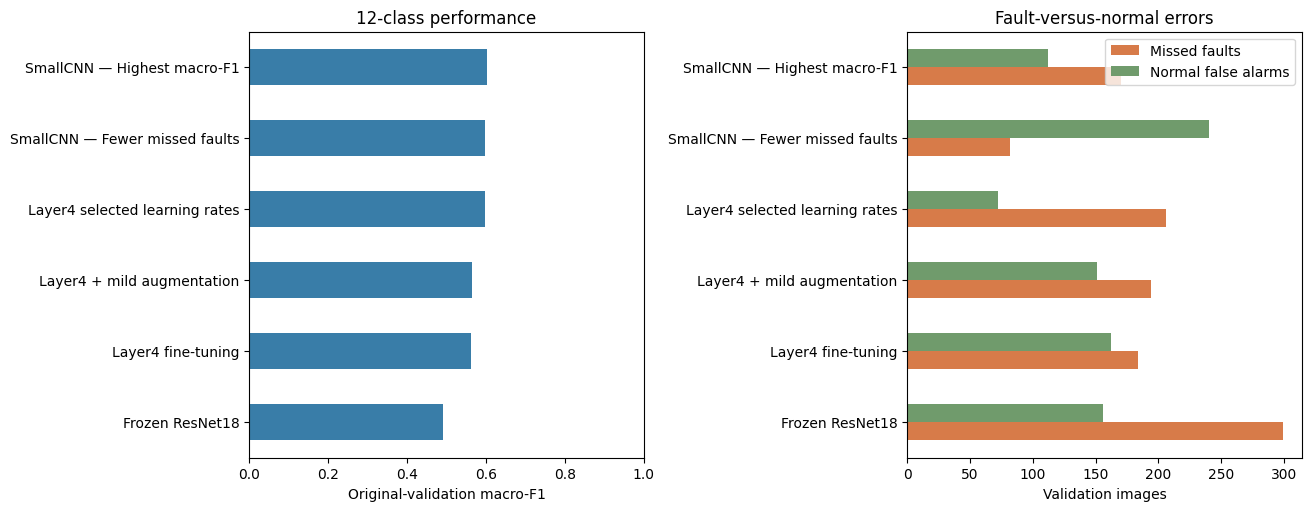

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
comparison_table["macro_f1"].plot.barh(ax=axes[0], color="#397da8")
axes[0].set(xlim=(0, 1), xlabel="Original-validation macro-F1", ylabel="", title="12-class performance")
comparison_table[["faults_called_normal", "normal_called_fault"]].rename(columns={
    "faults_called_normal": "Missed faults", "normal_called_fault": "Normal false alarms"
}).plot.barh(ax=axes[1], color=["#d77b49", "#709b6c"])
axes[1].set(xlabel="Validation images", ylabel="", title="Fault-versus-normal errors")
plt.show()

### What does this comparison support?

- The historical frozen ResNet improved on the **older** CNNs used in its original report. It does not beat our newly optimised SmallCNN references on macro-F1.
- The selected layer4 ResNet has macro-F1 **0.5965**, compared with **0.6012** for the SmallCNN scheduler reference. Their small difference, unequal search budgets and repeated validation selection do not establish a reliable winner.
- Selected ResNet has **72** normal false alarms, versus **112** for the SmallCNN scheduler reference, but more missed faults (**206 versus 170**). The other SmallCNN reference misses **82** faults but raises **240** normal false alarms.
- Accuracy alone would hide these differences. Keep 12-class macro-F1, per-class recall, balanced accuracy and both binary error counts visible.

Full per-class/confusion evidence for the historical selected ResNet is not present as a tracked metrics JSON in this checkout. We do not invent those values. The augmentation trial has tracked per-class evidence, which is shown below and labelled separately.

,support,precision,recall,f1
Hot-Spot,37.0,0.228,0.351,0.277
Soiling,31.0,0.333,0.387,0.358
Cell-Multi,193.0,0.464,0.399,0.429
Offline-Module,123.0,0.426,0.585,0.493
Hot-Spot-Multi,37.0,0.411,0.622,0.495
Cell,280.0,0.567,0.514,0.539
Shadowing,156.0,0.705,0.474,0.567
Diode-Multi,26.0,0.652,0.577,0.612
Cracking,141.0,0.697,0.603,0.646
Vegetation,245.0,0.629,0.665,0.647


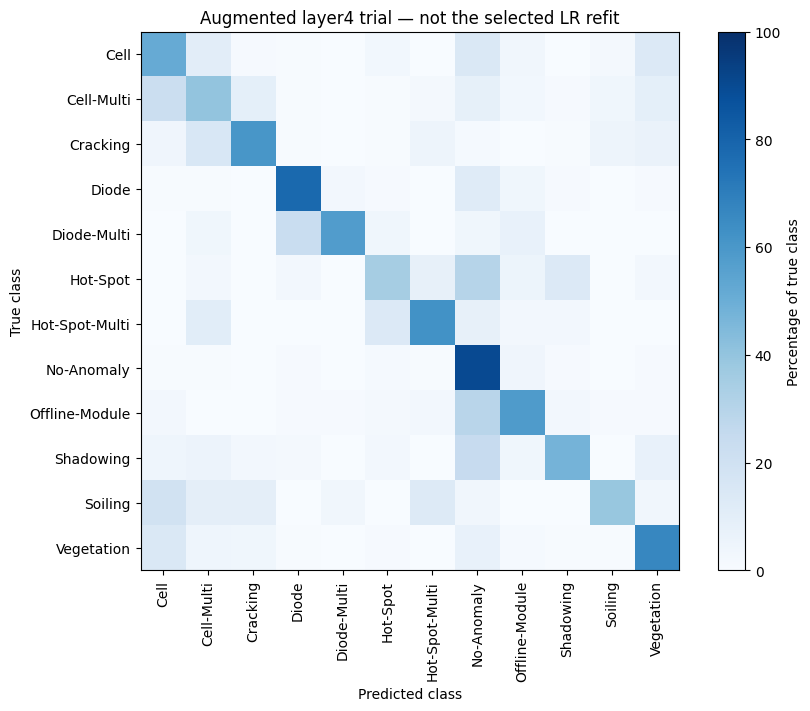

In [7]:
display(pd.DataFrame(augmented["per_class"]).T.sort_values("f1").round(3))
cm = np.asarray(augmented["confusion_matrix"])
assert cm.sum() == 2988
fig, ax = plt.subplots(figsize=(9, 7), layout="constrained")
im = ax.imshow(100 * cm / cm.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=100)
ax.set(xticks=range(12), yticks=range(12), xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
       xlabel="Predicted class", ylabel="True class", title="Augmented layer4 trial — not the selected LR refit")
ax.tick_params(axis="x", labelrotation=90)
fig.colorbar(im, ax=ax, label="Percentage of true class")
plt.show()

## 6. Reproducing the experiments through shared scripts

Running this notebook normally reads the recorded results and inspects the code. It does **not** download weights or launch full training. Use the helper below to run a selected stage deliberately. The default is the script's short smoke run; full training requires `full=True`, verifies the dataset first and refuses an existing output folder.

Pretrained weights are downloaded separately by `scripts/fetch_resnet18_weights.py` and verified against their pinned SHA-256. Fine-tuning also requires the **exact historical frozen parent checkpoint** named in its plan. A newly reproduced parent is not silently substituted: if its bytes differ, record a new plan and provenance. Original historical run IDs must not be overwritten.

In [8]:
SCRIPTS = {"frozen": "train_resnet18.py", "layer4": "finetune_resnet18.py",
           "augmentation": "finetune_resnet18.py", "selected": "finetune_resnet18_selected.py"}

def run_resnet_stage(stage, *, full=False):
    if stage not in SCRIPTS:
        raise ValueError(f"Choose one of {tuple(SCRIPTS)}; CV has its own recorded protocol.")
    plan = plans[stage]
    for path_key, hash_key in (("pretrained_weights", "pretrained_sha256"),
                               ("parent_checkpoint", "parent_checkpoint_sha256")):
        if path_key not in plan:
            continue
        path = ROOT / plan[path_key]
        if not path.is_file():
            raise FileNotFoundError(f"Required local artifact is missing: {path}")
        if hashlib.sha256(path.read_bytes()).hexdigest() != plan[hash_key]:
            raise ValueError(f"Required artifact checksum differs: {path}")
    if full and (ROOT / "runs" / plan["run_id"]).exists():
        raise FileExistsError("Run already exists. Create a new explicit plan/run ID before reproducing.")
    env = dict(os.environ)
    env["PYTHONPATH"] = str(ROOT / "src") + os.pathsep + env.get("PYTHONPATH", "")
    if full:
        subprocess.run([sys.executable, "scripts/create_split.py", "--verify-only"],
                       cwd=ROOT, env=env, check=True)
    command = [sys.executable, "scripts/" + SCRIPTS[stage], "--plan", "configs/" + PLAN_FILES[stage]]
    if full:
        command.append("--full")
    return subprocess.run(command, cwd=ROOT, env=env, check=True)

# Deliberate actions only; leave commented for ordinary notebook use.
# run_resnet_stage("frozen")                # short smoke check
# run_resnet_stage("frozen", full=True)     # one bounded full trial
# run_resnet_stage("selected", full=True)   # requires the exact parent checkpoint

artifacts = []
for stage in SCRIPTS:
    plan = plans[stage]
    artifacts.append({"Stage": stage,
        "Pretrained weights present": (ROOT / plan["pretrained_weights"]).is_file(),
        "Parent checkpoint present": (ROOT / plan["parent_checkpoint"]).is_file()
            if "parent_checkpoint" in plan else "Not required",
        "Historical run folder present": (ROOT / "runs" / plan["run_id"]).is_dir()})
display(pd.DataFrame(artifacts).set_index("Stage"))

,Pretrained weights present,Parent checkpoint present,Historical run folder present
Stage,,,
frozen,True,Not required,False
layer4,True,False,False
augmentation,True,False,False
selected,True,False,False


## 7. Decisions and what remains

We have evidence for transfer learning and partial fine-tuning in this repo; they are not untried ideas. The immediate outcome is a documented comparison with our stronger current CNN references, not a new claim of improvement.

Before another fit, recover or deliberately reproduce the missing historical artifacts, define one change and its reference, and record the budget. Additional random-seed checks remain deferred. Keep the original test partition unused while making choices.

The historical report also explored a validation-selected routing threshold and an external dataset with a different taxonomy. Those are separate analyses: a thresholded binary routing score must not replace 12-class argmax metrics in this comparison. The external result exposed substantial domain shift and does not establish 12-class performance on unseen sites.

**Progress in this notebook:** existing frozen, layer4, augmentation and learning-rate experiments explained; current SmallCNN comparisons added; reproducibility prerequisites made visible. **New local reproductions:** the following section records the fresh runs separately from these historical results. Ordinary notebook execution still does not launch training.

References in the repository: `results/resnet18-frozen-v1-validation.md`, `results/validation-development-2026-10-22.md`, `results/resnet18-layer4-augmentation-v1/` and `notebooks/02_baseline_experiments.ipynb`.

## 8. Fresh local reproduction: frozen head → layer4

After reviewing the historical evidence, we restored TorchVision's pinned pretrained weights and verified the full frozen dataset. We use new run IDs so the historical outputs remain untouched. Both runs use seed **2112**, batch **64**, four local CPU threads and the same split/weighted training loss as before.

**Before running:** reproduce the original frozen protocol (Adam 0.001, up to five epochs, patience two, 390-second cap), verify its saved checkpoint, then use that exact new checkpoint as the parent for the first layer4 protocol (head rate 0.0001, layer4 rate 0.00001, up to four epochs, patience two, 480-second cap). These are the original bounded protocols, not a claim to optimise ResNet beyond the previous experiments. The inherited frozen-plan smoke estimates are historical; current hardware/software and actual epoch timings are recorded separately.

The layer4 reproduction does not use the later CV-selected learning rates. This keeps the first frozen-to-fine-tuned progression clear. Historical source environments/checkpoint bytes may differ; similar metrics alone would not prove bit-for-bit reproduction.

Each run saves source snapshots and hashes. `scripts/verify_resnet_checkpoint.py` reloads the selected checkpoint and checks **every validation record and probability vector** against saved predictions, recomputes the metrics and verifies provenance. It never constructs a test loader. Test image bytes were hashed only for dataset integrity verification; no test predictions are produced.

In [9]:
fresh_path = ROOT / "results/resnet18-reproduction-v1.json"
fresh_runs = []
if fresh_path.is_file():
    fresh = json.loads(fresh_path.read_text())
    assert fresh["test_evaluated"] is False
    fresh_runs = fresh["experiments"]
    current_rows = []
    for result in fresh_runs:
        m, summary = result["metrics"], result["summary"]
        assert result["verification"]["checkpoint_predictions_verified"]
        current_rows.append({"Model": result["label"], "Macro-F1": m["macro_f1"],
            "Accuracy": m["accuracy"], "Balanced accuracy": m["balanced_accuracy"],
            "Missed faults": m["faults_called_normal"], "Normal false alarms": m["normal_called_fault"],
            "Best / completed epoch": f"{summary['best_epoch']} / {summary['epochs_completed']}",
            "Trainable parameters": result["provenance"]["trainable_parameters"]})
    for reference in cnn["models"]:
        m = reference["metrics"]
        current_rows.append({"Model": "SmallCNN — " + reference["role"],
            "Macro-F1": m["macro_f1"], "Accuracy": m["accuracy"],
            "Balanced accuracy": m["balanced_accuracy"], "Missed faults": m["faults_called_normal"],
            "Normal false alarms": m["normal_called_fault"], "Best / completed epoch": "See baseline notebook",
            "Trainable parameters": 47820})
    display(pd.DataFrame(current_rows).set_index("Model").round(4))
    for stage, filename in (("frozen_repro", "experiment-plan-resnet18-frozen-repro.json"),
                            ("layer4_repro", "experiment-plan-resnet18-layer4-repro.json")):
        PLAN_FILES[stage] = filename
        plans[stage] = json.loads((ROOT / "configs" / filename).read_text())
        SCRIPTS[stage] = "train_resnet18.py" if stage == "frozen_repro" else "finetune_resnet18.py"
else:
    print("Reproduction not yet documented; no completed result claimed.")

,Macro-F1,Accuracy,Balanced accuracy,Missed faults,Normal false alarms,Best / completed epoch,Trainable parameters
Model,,,,,,,
Fresh frozen ResNet18,0.4900,0.6921,0.4925,299,156,4 / 5,6156
Fresh layer4 ResNet18,0.5629,0.7319,0.5784,184,162,4 / 4,8394764
SmallCNN — Fewer missed faults,0.5964,0.7413,0.6183,82,240,See baseline notebook,47820
SmallCNN — Highest macro-F1,0.6012,0.7634,0.5934,170,112,See baseline notebook,47820


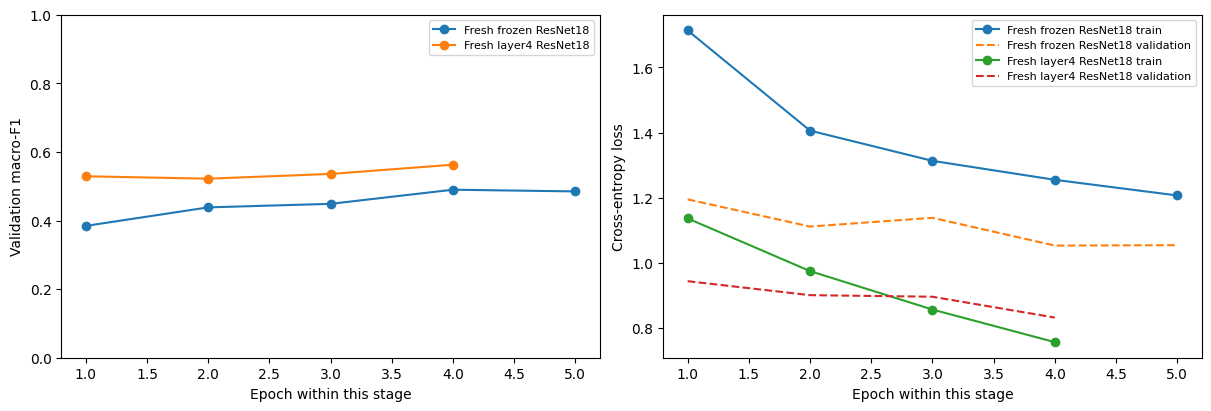

Train loss is class-weighted; validation loss is unweighted. Compare trends, not their absolute levels.
Fresh frozen ResNet18: per-class results (lowest F1 first)


,support,precision,recall,f1
Hot-Spot,37.0,0.207,0.162,0.182
Soiling,31.0,0.200,0.323,0.247
Cell-Multi,193.0,0.450,0.254,0.325
Offline-Module,123.0,0.392,0.398,0.395
Hot-Spot-Multi,37.0,0.350,0.568,0.433
Shadowing,156.0,0.569,0.397,0.468
Cell,280.0,0.487,0.482,0.485
Diode-Multi,26.0,0.519,0.538,0.528
Vegetation,245.0,0.636,0.571,0.602
Cracking,141.0,0.687,0.638,0.662


Fresh layer4 ResNet18: per-class results (lowest F1 first)


,support,precision,recall,f1
Hot-Spot,37.0,0.325,0.351,0.338
Soiling,31.0,0.318,0.452,0.373
Cell-Multi,193.0,0.462,0.342,0.393
Hot-Spot-Multi,37.0,0.365,0.622,0.460
Offline-Module,123.0,0.412,0.553,0.472
Cell,280.0,0.551,0.539,0.545
Shadowing,156.0,0.669,0.532,0.593
Diode-Multi,26.0,0.593,0.615,0.604
Vegetation,245.0,0.611,0.641,0.625
Cracking,141.0,0.696,0.617,0.654


In [10]:
if fresh_runs:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
    for result in fresh_runs:
        history = result["history"]
        epochs = [row["epoch"] for row in history]
        axes[0].plot(epochs, [row["validation_macro_f1"] for row in history], marker="o", label=result["label"])
        axes[1].plot(epochs, [row["train"]["loss"] for row in history], marker="o", label=result["label"] + " train")
        axes[1].plot(epochs, [row["validation_loss"] for row in history], linestyle="--", label=result["label"] + " validation")
    axes[0].set(xlabel="Epoch within this stage", ylabel="Validation macro-F1", ylim=(0, 1))
    axes[1].set(xlabel="Epoch within this stage", ylabel="Cross-entropy loss")
    for ax in axes:
        ax.legend(fontsize=8)
    plt.show()
    print("Train loss is class-weighted; validation loss is unweighted. Compare trends, not their absolute levels.")
    for result in fresh_runs:
        print(result["label"] + ": per-class results (lowest F1 first)")
        display(pd.DataFrame(result["metrics"]["per_class"]).T.sort_values("f1").round(3))

### What changed, and what did we learn?

The frozen stage learns a new way to combine fixed ImageNet features into our 12 class scores. Fine-tuning changes the later feature filters themselves: backpropagation computes gradients through layer4 and the head, and Adam updates only the parameters marked trainable. Earlier stages and BatchNorm remain frozen. The two stages therefore differ in both trainable capacity and their stage-specific learning rates; the comparison evaluates this complete staged protocol.

The final decision record below is generated from the fresh saved metrics, rather than assuming fine-tuning must help. These are development results with the same seed and original validation set; no extra-seed confirmation or test evaluation was requested here.

In [11]:
if fresh_runs:
    frozen_result, tuned_result = fresh_runs
    a, b = frozen_result["metrics"], tuned_result["metrics"]
    print(f"Layer4 versus fresh frozen: macro-F1 {b['macro_f1'] - a['macro_f1']:+.4f}; "
          f"accuracy {b['accuracy'] - a['accuracy']:+.4f}; "
          f"missed faults {b['faults_called_normal'] - a['faults_called_normal']:+d}; "
          f"normal false alarms {b['normal_called_fault'] - a['normal_called_fault']:+d}.")
    for reference in cnn["models"]:
        r = reference["metrics"]
        print(f"Layer4 versus SmallCNN ({reference['role']}): "
              f"macro-F1 {b['macro_f1'] - r['macro_f1']:+.4f}; "
              f"missed faults {b['faults_called_normal'] - r['faults_called_normal']:+d}; "
              f"normal false alarms {b['normal_called_fault'] - r['normal_called_fault']:+d}.")
    print("Historical CV-selected ResNet remains a separate result at macro-F1 0.5965; it was not rerun here.")
    print("Keep the test split reserved. Additional seed checks remain deferred.")

Layer4 versus fresh frozen: macro-F1 +0.0729; accuracy +0.0398; missed faults -115; normal false alarms +6.
Layer4 versus SmallCNN (Fewer missed faults): macro-F1 -0.0335; missed faults +102; normal false alarms -78.
Layer4 versus SmallCNN (Highest macro-F1): macro-F1 -0.0383; missed faults +14; normal false alarms +50.
Historical CV-selected ResNet remains a separate result at macro-F1 0.5965; it was not rerun here.
Keep the test split reserved. Additional seed checks remain deferred.


### Completed-run decision record

Both fresh runs selected epoch **4**. Frozen ResNet reached macro-F1 **0.4900**, accuracy **69.21%**, **299** missed faults and **156** normal false alarms. Layer4 fine-tuning reached macro-F1 **0.5629**, accuracy **73.19%**, **184** missed faults and **162** normal false alarms. It improved macro-F1 by **0.0729** and reduced missed faults by **115**, with six extra normal false alarms.

The fresh frozen checkpoint SHA-256 exactly matches the historical parent checksum. Both fresh checkpoints reproduced all **2,988** saved validation prediction records, including their probability vectors; their recomputed metrics and source snapshots also passed verification. The full suite passed **23 tests with one existing skipped placeholder**, including the new check that layer4/head update while earlier weights and BatchNorm stay fixed.

**Retain the current SmallCNN references.** This first layer4 protocol did not surpass them on macro-F1. The later historical learning-rate-selected ResNet remains a separate result (**0.5965**); this session did not rerun its CV selection or its six-epoch refit. Further experimentation should start from a stated hypothesis rather than treating this reproduction as a new optimum.

Current timings were about **298 seconds** for frozen training and **405 seconds** for layer4; checkpoint verification and documentation add overhead. The current layer4 run was slower than the historical run, which illustrates why timings are environment-dependent even when reported metrics agree.

New plans: `configs/experiment-plan-resnet18-frozen-repro.json` and `configs/experiment-plan-resnet18-layer4-repro.json`. Shareable results: `results/resnet18-reproduction-v1.json` and `.md`. Checkpoints and full predictions remain local under the two new `runs/*-repro-s2112-v1` folders. No test inference or additional-seed checks were performed.

## 9. ResNet optimisation: selected rates, longer training and scheduling

**Question before running:** the first layer4 reproduction reaches macro-F1 0.5629, but our SmallCNN scheduler reference reaches 0.6012. Can the stronger recorded ResNet learning rates, more training, or a learning-rate reduction close that gap?

The recorded stronger ResNet uses head/layer4 rates **0.0003 / 0.00003**. Its historical six-epoch macro-F1 was **0.5965**. The original CV summary is not present locally, so we use the shared general layer4 runner with a new reproduction plan, explicitly citing the tracked historical settings. We do not bypass the original CV-refit script's evidence check or claim a new cross-validation result.

| Arm | Change / purpose | Epoch cap | Early-stop patience | Seconds cap |
|---|---|---:|---:|---:|
| selected6 | Reproduce the recorded stronger rates | 6 | 2 | 720 |
| longer10 | Keep those rates; increase duration and patience | 10 | 4 | 1,200 |
| plateau10 | Match longer10; halve both rates after two epochs without a new best validation macro-F1 | 10 | 4 | 1,200 |

All three are fresh fits from the **same checksum-pinned frozen parent**, not continuations from whichever earlier fine-tuned model happens to be available. Seed 2112, batch 64, Adam, class weighting, preprocessing and the trainable layers stay fixed. The scheduler uses validation macro-F1, factor 0.5, patience 1 (two non-improving epochs), absolute threshold zero and minimum rate 1e-7. It acts after validation, so the new rates apply to the following epoch.

The longer arm changes both epoch allowance and stopping patience; interpret that as a longer-training protocol. Comparing plateau10 with longer10 isolates the scheduler under matched caps. No augmentation, AdamW, additional seeds or other unplanned trials are included in this bounded three-trial phase. Checkpoint verification adds overhead to the caps, which are checked between epochs. The test split remains reserved.

The rationale follows PyTorch's distinction between a [fixed feature extractor and fine-tuning](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html). Plateau scheduling monitors a chosen metric and reduces the rate after stalled progress; see the [official scheduler documentation](https://docs.pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.ReduceLROnPlateau.html). Our local two-group test verifies the settings used here. These sources explain the mechanisms; our recorded trials establish whether they help on this dataset.

In [12]:
optim_protocol = json.loads((ROOT / "configs/resnet18-optimisation-v1.json").read_text())
for arm in optim_protocol["planned_trials"]:
    stage = "optim_" + arm["arm"]
    PLAN_FILES[stage] = Path(arm["plan"]).name
    plans[stage] = json.loads((ROOT / arm["plan"]).read_text())
    SCRIPTS[stage] = "finetune_resnet18.py"
# The shared helper refuses existing run IDs; ordinary notebook execution does not train.
# run_resnet_stage("optim_selected6")
# run_resnet_stage("optim_selected6", full=True)

ledger_path = ROOT / "results/resnet18-optimisation-v1-ledger.json"
if ledger_path.is_file():
    optim_ledger = json.loads(ledger_path.read_text())
    display(pd.DataFrame(optim_ledger["trials"])[["arm", "status", "run_id"]].set_index("arm"))
else:
    print("Protocol recorded; trials not yet run.")

,status,run_id
arm,,
selected6,completed_verified,resnet18-optim-selected6-s2112-v1
longer10,completed_verified,resnet18-optim-longer10-s2112-v1
plateau10,completed_verified,resnet18-optim-plateau10-s2112-v1


### Recorded outcomes and comparison

The following cells read tracked result snapshots, including the best checkpoint's per-class metrics, histories, source provenance and reload verification. Missing snapshots mean a result has not been documented yet. Planned slots are not evidence of completed training.

Accuracy is exact 12-class accuracy. Missed faults count anomalous images predicted No-Anomaly; normal false alarms count No-Anomaly images predicted as any fault. These measures answer different questions, so a higher macro-F1 alone does not settle the choice of reference.

In [13]:
optim_runs = []
optim_path = ROOT / "results/resnet18-optimisation-v1.json"
if optim_path.is_file():
    optim_snapshot = json.loads(optim_path.read_text())
    assert optim_snapshot["test_evaluated"] is False
    optim_runs = optim_snapshot["experiments"]
    rows = []
    for result in optim_runs:
        m, summary = result["metrics"], result["summary"]
        assert result["verification"]["checkpoint_predictions_verified"]
        rows.append({"Model": "ResNet " + result["arm"], "Macro-F1": m["macro_f1"],
            "Accuracy": m["accuracy"], "Balanced accuracy": m["balanced_accuracy"],
            "Missed faults": m["faults_called_normal"], "Normal false alarms": m["normal_called_fault"],
            "Best / completed epoch": f"{summary['best_epoch']} / {summary['epochs_completed']}",
            "LR reductions": result["lr_reduction_epochs"], "Stop": summary["stop_reason"]})
    for reference in cnn["models"]:
        m = reference["metrics"]
        rows.append({"Model": "SmallCNN — " + reference["role"], "Macro-F1": m["macro_f1"],
            "Accuracy": m["accuracy"], "Balanced accuracy": m["balanced_accuracy"],
            "Missed faults": m["faults_called_normal"], "Normal false alarms": m["normal_called_fault"]})
    display(pd.DataFrame(rows).set_index("Model").round(4))
    print("First six validation macro-F1 values of selected6 and longer10 match:",
          optim_snapshot["selected6_longer10_common_prefix_matches"])
else:
    print("Optimisation results not yet documented.")

,Macro-F1,Accuracy,Balanced accuracy,Missed faults,Normal false alarms,Best / completed epoch,LR reductions,Stop
Model,,,,,,,,
ResNet selected6,0.5965,0.7687,0.5705,206,72,6 / 6,[],max_epochs
ResNet longer10,0.6158,0.7838,0.5816,217,52,10 / 10,[],max_epochs
ResNet plateau10,0.6261,0.7908,0.5966,196,55,10 / 10,[9],max_epochs
SmallCNN — Fewer missed faults,0.5964,0.7413,0.6183,82,240,NaN,NaN,NaN
SmallCNN — Highest macro-F1,0.6012,0.7634,0.5934,170,112,NaN,NaN,NaN


First six validation macro-F1 values of selected6 and longer10 match: True


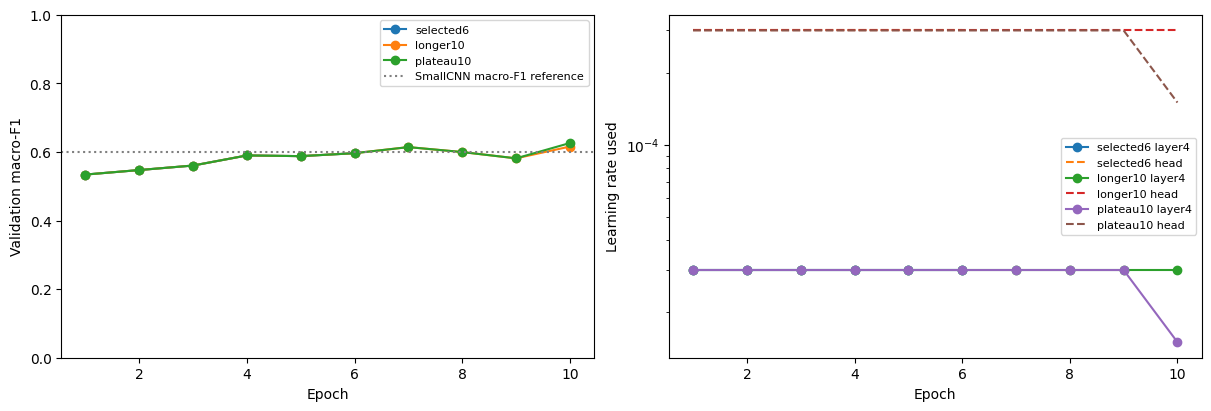

Highest validation macro-F1 in this phase: plateau10


,support,precision,recall,f1
Soiling,31.0,0.440,0.355,0.393
Hot-Spot-Multi,37.0,0.469,0.405,0.435
Hot-Spot,37.0,0.484,0.405,0.441
Cell-Multi,193.0,0.506,0.425,0.462
Cell,280.0,0.613,0.561,0.586
Offline-Module,123.0,0.692,0.602,0.643
Shadowing,156.0,0.740,0.603,0.664
Cracking,141.0,0.697,0.652,0.674
Vegetation,245.0,0.719,0.690,0.704
Diode-Multi,26.0,0.842,0.615,0.711


Versus SmallCNN (Fewer missed faults): macro-F1 +0.0297; missed faults +114; normal false alarms -185.
Versus SmallCNN (Highest macro-F1): macro-F1 +0.0249; missed faults +26; normal false alarms -57.


In [14]:
if optim_runs:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
    for result in optim_runs:
        history = result["history"]
        epochs = [r["epoch"] for r in history]
        axes[0].plot(epochs, [r["validation_macro_f1"] for r in history], marker="o", label=result["arm"])
        axes[1].plot(epochs, [r["learning_rates"][0] for r in history], marker="o", label=result["arm"] + " layer4")
        axes[1].plot(epochs, [r["learning_rates"][1] for r in history], linestyle="--", label=result["arm"] + " head")
    axes[0].axhline(0.6011947353233656, color="gray", linestyle=":", label="SmallCNN macro-F1 reference")
    axes[0].set(xlabel="Epoch", ylabel="Validation macro-F1", ylim=(0, 1))
    axes[1].set(xlabel="Epoch", ylabel="Learning rate used", yscale="log")
    for ax in axes:
        ax.legend(fontsize=8)
    plt.show()
    optim_best = max(optim_runs, key=lambda r: r["metrics"]["macro_f1"])
    print("Highest validation macro-F1 in this phase:", optim_best["arm"])
    display(pd.DataFrame(optim_best["metrics"]["per_class"]).T.sort_values("f1").round(3))
    best_m = optim_best["metrics"]
    for reference in cnn["models"]:
        m = reference["metrics"]
        print(f"Versus SmallCNN ({reference['role']}): "
              f"macro-F1 {best_m['macro_f1'] - m['macro_f1']:+.4f}; "
              f"missed faults {best_m['faults_called_normal'] - m['faults_called_normal']:+d}; "
              f"normal false alarms {best_m['normal_called_fault'] - m['normal_called_fault']:+d}.")

### Interpretation rules agreed before reviewing results

A longer run must improve the **selected validation checkpoint**, not merely its training score, to justify adopting it as a stronger development reference. If a cap or early stopping prevents further epochs, report that rather than claiming ten epochs ran.

Inspect whether the scheduler actually reduced the rates. If it never activated, any identical outcome is not evidence that a reduction helped. If it activates but loses, retain that negative result. A model that beats SmallCNN on this validation macro-F1 is a promising development candidate, not a confirmed generalisation improvement: the same seed and repeatedly used validation partition remain limitations. Additional seeds stay deferred; test inference stays untouched.

In [15]:
if optim_runs:
    small_reference = next(r for r in cnn["models"] if r["role"] == "Highest macro-F1")
    first_trial = next(r for r in optim_runs if r["arm"] == "selected6")
    per_class_comparison = pd.DataFrame({
        "SmallCNN reference F1": {k: v["f1"] for k, v in small_reference["metrics"]["per_class"].items()},
        "Six-epoch ResNet F1": {k: v["f1"] for k, v in first_trial["metrics"]["per_class"].items()},
        "Best phase ResNet F1": {k: v["f1"] for k, v in optim_best["metrics"]["per_class"].items()},
        "Validation images": {k: v["support"] for k, v in optim_best["metrics"]["per_class"].items()},
    })
    per_class_comparison["Best ResNet minus SmallCNN"] = (
        per_class_comparison["Best phase ResNet F1"] - per_class_comparison["SmallCNN reference F1"])
    display(per_class_comparison.sort_values("Best ResNet minus SmallCNN").round(3))
    print("Differences describe this reused validation set; small supports make rare-class estimates uncertain.")

,SmallCNN reference F1,Six-epoch ResNet F1,Best phase ResNet F1,Validation images,Best ResNet minus SmallCNN
Hot-Spot-Multi,0.564,0.493,0.435,37,-0.129
Cell,0.611,0.590,0.586,280,-0.025
Diode,0.884,0.874,0.879,223,-0.004
Hot-Spot,0.434,0.444,0.441,37,0.007
No-Anomaly,0.908,0.911,0.920,1496,0.012
Diode-Multi,0.696,0.667,0.711,26,0.015
Cell-Multi,0.429,0.405,0.462,193,0.033
Soiling,0.355,0.338,0.393,31,0.038
Cracking,0.628,0.683,0.674,141,0.046
Vegetation,0.646,0.615,0.704,245,0.058


Differences describe this reused validation set; small supports make rare-class estimates uncertain.


## 10. One-hour adaptive follow-up and compute comparison

**User-requested window:** 27 October 2026, **10:13:11–11:13:11 Australia/Sydney** (23:13:11–00:13:11 UTC). The window begins while longer10 is already running, so full-run timing for carried-over trials includes work before this hour. The user also requested explicit comparison of training time and compute.

Finish and verify the initial three trials first. Then choose feasible follow-ups from the recorded candidates: **AdamW weight decay**, **layer3+layer4 adaptation**, or **mild training-only augmentation**. A candidate is not a completed experiment; exact plans are written before each fit. No full trial starts unless its cap, an epoch-overrun allowance and verification fit before the deadline with time reserved for documentation. Further seeds stay deferred; original test inference stays unused.

Layer3 adaptation tests whether an earlier residual stage needs to change for thermal images. It uses a smaller layer3 rate, while earlier stages and BatchNorm stay frozen. AdamW tests a declared optimiser/decay change against the selected longer reference, motivated by the large gap between training and validation accuracy. These are hypotheses, not guaranteed improvements.

### What the timing comparison means

- **Run seconds** include setup, training, validation and saving. The initial three trials and historical SmallCNN records cannot be retrospectively separated into pure training seconds. Later adaptive trials have explicit training and validation phase timers, including loader iteration and model work; they are not kernel-only profiler timings. The SmallCNN runner also includes checkpoint reload verification and a clean training-fit evaluation in its reported total; the ResNet runner reports external checkpoint verification separately, so the timing scopes are not perfectly identical.
- **Completed epochs**, optimiser updates and training-image presentations help explain the budget. A model selected at an earlier epoch may still have spent compute on later epochs before stopping.
- **Incremental fine-tuning cost** is separate from the approximately five-minute frozen-head parent run. The parent is reused across trials; ImageNet pretraining cost is not measured or included.
- **Trainable versus total parameters** describe different things: frozen ResNet layers still require a forward pass. ResNet also uses 80×48 inputs after resizing, versus SmallCNN's native 40×24. Parameter count alone is not a measurement of FLOPs, peak RAM or energy.
- All recorded comparisons use four local CPU threads. Historical SmallCNN times are not a controlled same-session hardware benchmark. Runtime can vary with system load and thermal conditions.
- A short **model-only inference benchmark**, run after training on synthetic inputs, separately measures prediction latency. It does not load any test images and excludes image decoding and application overhead.

In [16]:
from pv_fault.finetuning import configure_resnet_finetuning
print(inspect.getsource(configure_resnet_finetuning))
adaptive_settings = []
for filename in sorted((ROOT / "configs").glob("experiment-plan-resnet18-hour-*.json")):
    plan = json.loads(filename.read_text())
    adaptive_settings.append({"Arm": plan["arm"], "Trainable stages": ", ".join(plan["trainable_stages"]),
        "Optimiser": plan["optimizer"], "Weight decay": plan["weight_decay"],
        "Layer3 LR": plan.get("layer3_learning_rate"), "Layer4 LR": plan["layer4_learning_rate"],
        "Head LR": plan["head_learning_rate"], "Epoch cap": plan["max_epochs"],
        "Seconds cap": plan["max_elapsed_seconds"]})
if adaptive_settings:
    display(pd.DataFrame(adaptive_settings).set_index("Arm"))

def configure_resnet_finetuning(model, stages=("layer4",)):
    """Train layer4 or layer3+layer4 and the head; keep BatchNorm fixed.

    ResNet18Thermal.train() keeps running statistics frozen. This function
    additionally freezes BatchNorm affine parameters and earlier stage weights.
    """
    stages = tuple(stages)
    if stages not in (("layer4",), ("layer3", "layer4")):
        raise ValueError("Choose layer4 or layer3+layer4 in their forward order.")
    for parameter in model.backbone.parameters():
        parameter.requires_grad_(False)
    for stage in stages:
        for parameter in getattr(model.backbone, stage).parameters():
            parameter.requires_grad_(True)
    for module in model.backbone.modules():
        if isinstance(module, nn.BatchNorm2d):
            for parameter in module.parameters():
                parameter.requires_grad_(False)
    for parameter in model.backbone.fc.parameters():
        parameter.requires_grad_(True)



,Trainable stages,Optimiser,Weight decay,Layer3 LR,Layer4 LR,Head LR,Epoch cap,Seconds cap
Arm,,,,,,,,
adamw,layer4,adamw,0.0001,NaN,0.00003,0.0003,10,780
layer3_layer4,"layer3, layer4",adam,0.0000,0.00001,0.00003,0.0003,8,780


In [17]:
hour_path = ROOT / "results/resnet18-hour-v1.json"
hour_runs = []
if hour_path.is_file():
    hour_snapshot = json.loads(hour_path.read_text())
    assert hour_snapshot["test_evaluated"] is False
    hour_runs = hour_snapshot["adaptive_experiments"]
    display(pd.DataFrame(hour_snapshot["candidate_ledger"]).set_index("candidate"))
    for result in hour_runs:
        assert result["verification"]["checkpoint_predictions_verified"]
    display(pd.DataFrame(hour_snapshot["score_comparison"]).set_index("Model").round(4))
else:
    print("Hour follow-up still in progress; no additional completed result claimed.")

,status,plan,run_id,control_run_id,started_utc,training_process_seconds,verification_process_seconds,finished_utc,macro_f1
candidate,,,,,,,,,
adamw,completed_verified,configs/experiment-plan-resnet18-hour-adamw.json,resnet18-hour-adamw-s2112-v1,resnet18-optim-plateau10-s2112-v1,2026-10-26T23:34:29.790525+00:00,824.029513,13.380884,2026-10-26T23:48:27.231391+00:00,0.607954
layer3_layer4,completed_verified,configs/experiment-plan-resnet18-hour-layer3_l...,resnet18-hour-layer3_layer4-s2112-v1,resnet18-optim-plateau10-s2112-v1,2026-10-26T23:48:30.754495+00:00,828.468865,12.166036,2026-10-27T00:02:31.395381+00:00,0.608686
mild_augmentation,not_run_budget_priority,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Macro-F1,Accuracy,Balanced accuracy,Missed faults,Normal false alarms
Model,,,,,
ResNet selected6,0.5965,0.7687,0.5705,206,72
ResNet longer10,0.6158,0.7838,0.5816,217,52
ResNet plateau10,0.6261,0.7908,0.5966,196,55
ResNet adamw,0.6080,0.7704,0.5980,141,137
ResNet layer3_layer4,0.6087,0.7801,0.5774,204,58
SmallCNN fewer missed faults,0.5964,0.7413,0.6183,82,240
SmallCNN highest macro-F1,0.6012,0.7634,0.5934,170,112


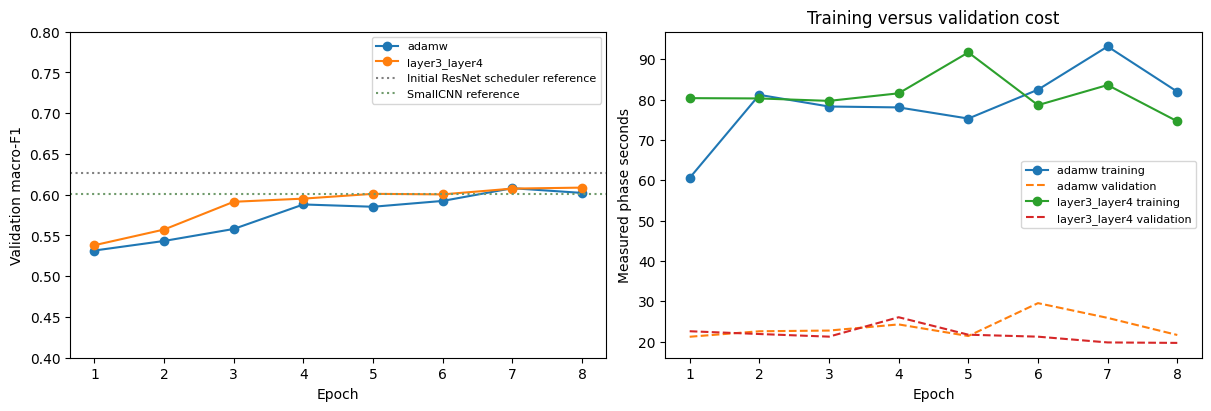

In [18]:
if hour_runs:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
    for result in hour_runs:
        history = result["history"]
        epochs = [row["epoch"] for row in history]
        axes[0].plot(epochs, [row["validation_macro_f1"] for row in history], marker="o", label=result["arm"])
        axes[1].plot(epochs, [row["train_seconds"] for row in history], marker="o", label=result["arm"] + " training")
        axes[1].plot(epochs, [row["validation_loss_seconds"] + row["validation_prediction_seconds"] for row in history],
                     linestyle="--", label=result["arm"] + " validation")
    axes[0].axhline(0.6260848329355161, color="gray", linestyle=":", label="Initial ResNet scheduler reference")
    axes[0].axhline(0.6011947353233656, color="#709b6c", linestyle=":", label="SmallCNN reference")
    axes[0].set(xlabel="Epoch", ylabel="Validation macro-F1", ylim=(0.4, 0.8))
    axes[1].set(xlabel="Epoch", ylabel="Measured phase seconds", title="Training versus validation cost")
    for ax in axes:
        ax.legend(fontsize=8)
    plt.show()

,Run minutes,Completed epochs,Selected epoch,Mean sec/epoch,Trainable params,Total params,CPU threads,Macro-F1,Optimiser updates,Training image presentations
Model,,,,,,,,,,
ResNet selected6,7.580,6,6,75.802,8394764,11182668,4,0.596,1308,83676
ResNet longer10,15.121,10,10,90.725,8394764,11182668,4,0.616,2180,139460
ResNet plateau10,15.469,10,10,92.814,8394764,11182668,4,0.626,2180,139460
ResNet adamw,13.705,8,7,102.788,8394764,11182668,4,0.608,1744,111568
ResNet layer3_layer4,13.779,8,8,103.340,10491916,11182668,4,0.609,1744,111568
SmallCNN fewer missed faults,2.768,30,29,5.536,47820,47820,4,0.596,6540,418380
SmallCNN highest macro-F1,2.072,28,23,4.439,47820,47820,4,0.601,6104,390488


Reported run wall time includes setup, training, validation and saving. SmallCNN totals also include reload verification and clean training-fit evaluation; ResNet external verification is separate. Historical SmallCNN timings are not a controlled same-session benchmark. Phase timers exist only for adaptive trials and include loader iteration as well as model work.


,Measured training seconds,Validation loss-pass seconds,Validation prediction-pass seconds,Other run seconds,External verification seconds
Model,,,,,
ResNet adamw,630.973,91.14,98.130,2.061,13.381
ResNet layer3_layer4,650.415,85.56,88.633,2.111,12.166


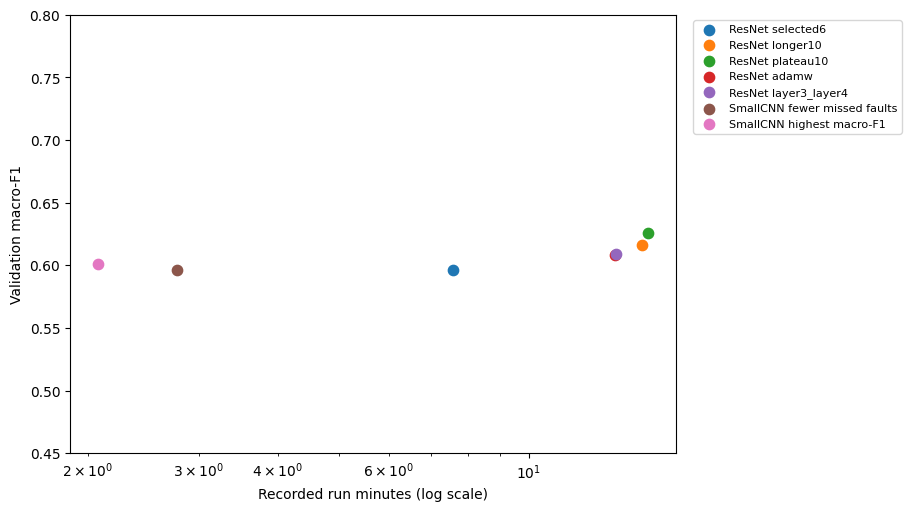

In [19]:
compute_path = ROOT / "results/resnet18-hour-v1-compute.json"
if compute_path.is_file():
    compute_snapshot = json.loads(compute_path.read_text())
    display(pd.DataFrame(compute_snapshot["run_comparison"]).set_index("Model").round(3))
    print(compute_snapshot["timing_scope"])
    if compute_snapshot["adaptive_phase_timings"]:
        display(pd.DataFrame(compute_snapshot["adaptive_phase_timings"]).set_index("Model").round(3))
    fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
    for row in compute_snapshot["run_comparison"]:
        ax.scatter(row["Run minutes"], row["Macro-F1"], s=55, label=row["Model"])
    ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.02, 1))
    ax.set(xlabel="Recorded run minutes (log scale)", ylabel="Validation macro-F1", xscale="log", ylim=(0.45, 0.8))
    plt.show()
else:
    print("Compute comparison will be populated from completed run records.")

In [20]:
benchmark_path = ROOT / "results/resnet18-hour-v1-inference-compute.json"
if benchmark_path.is_file():
    benchmark = json.loads(benchmark_path.read_text())
    inference_rows = []
    for record in benchmark["models"]:
        for timing in record["batches"]:
            inference_rows.append({"Model": record["model"], "Batch size": timing["batch_size"],
                "Median batch ms": timing["median_batch_ms"], "P90 batch ms": timing["p90_batch_ms"],
                "Amortised ms / image": timing["amortized_median_ms_per_image"],
                "Total parameters": record["total_parameters"],
                "Parameter storage MB": record["parameter_storage_bytes"] / 1e6})
    display(pd.DataFrame(inference_rows).set_index(["Model", "Batch size"]).round(3))
    print(benchmark["scope"])
    print(benchmark["memory_scope"])
else:
    print("Model-only latency benchmark runs after training finishes.")

Median batch ms  P90 batch ms  \
Model                       Batch size                                  
SmallCNN macro-F1 reference 1                     0.157         0.168   
                            64                    2.662         2.744   
Best phase ResNet           1                     2.623         2.664   
                            64                  181.978       186.078   

                                        Amortised ms / image  \
Model                       Batch size                         
SmallCNN macro-F1 reference 1                          0.157   
                            64                         0.042   
Best phase ResNet           1                          2.623   
                            64                         2.843   

                                        Total parameters  Parameter storage MB  
Model                       Batch size                                          
SmallCNN macro-F1 reference 1                      47820                 0.191  
                            64                     47820                 0.191  
Best phase ResNet           1                   11182668                44.731  
                            64                  11182668                44.731

Same synthetic grayscale inputs [N,1,40,24], model-only evaluation; no dataset images, loading or application overhead. Five warm-ups then twenty measurements per batch size. Run after all training.
Parameter storage only; excludes buffers, gradients, optimizer state and activations. Not peak RAM, FLOPs or energy.


### Decisions to record at the end of the hour

Compare the best verified ResNet with both SmallCNN references using macro-F1, accuracy, balanced accuracy and the two fault/normal error counts. Retain negative results and mark any skipped candidates explicitly. Separate a useful validation-selected candidate from evidence of a repeatable advantage.

Explain the cost of any improvement: total run time, per-epoch cost, trainable/total parameters, parent-run overhead and measured prediction latency. The compute comparison supports an engineering trade-off; it is not an energy, carbon or deployment-capacity estimate.

### Final selected ResNet: inspect remaining mistakes

The highest macro-F1 configuration still makes errors. The following matrix uses percentages within each true class, so rare classes remain visible. The examples select the lowest image ID in each of three error categories, rather than choosing dramatic cases. They illustrate mistakes; they do not establish their causes or prove labels are incorrect. These are validation images only.

Selected run: resnet18-optim-plateau10-s2112-v1


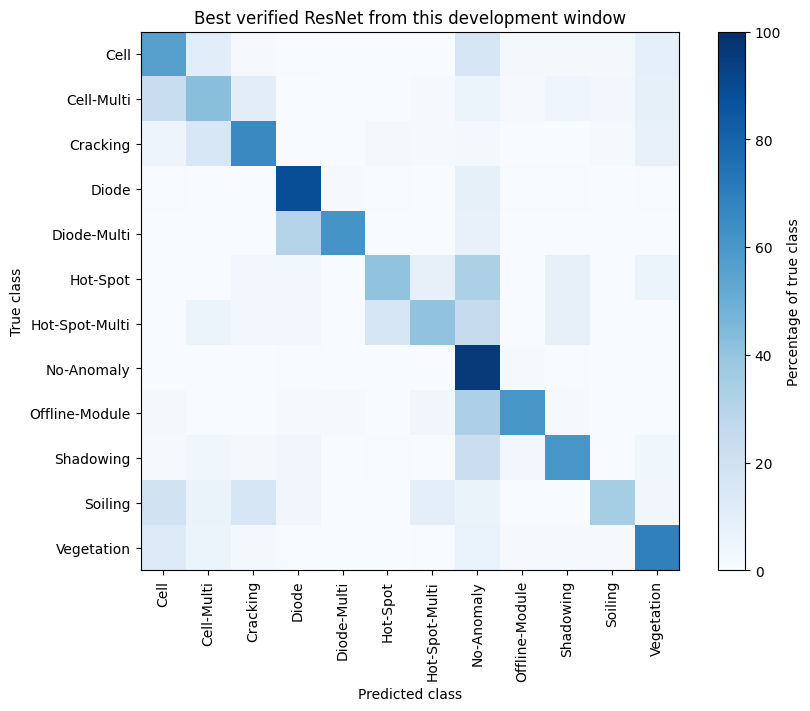

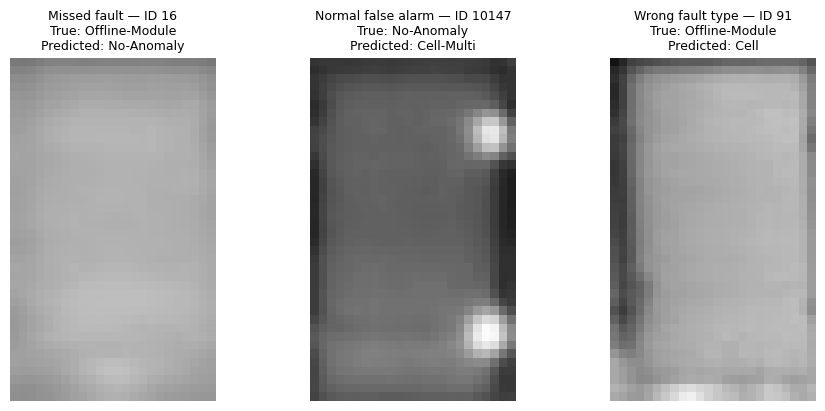

In [21]:
final_errors = json.loads((ROOT / "results/resnet18-hour-v1-errors.json").read_text())
assert final_errors["test_evaluated"] is False
print("Selected run:", final_errors["run_id"])
cm = np.asarray(final_errors["metrics"]["confusion_matrix"])
fig, ax = plt.subplots(figsize=(9, 7), layout="constrained")
im = ax.imshow(100 * cm / cm.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=100)
ax.set(xticks=range(12), yticks=range(12), xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
       xlabel="Predicted class", ylabel="True class", title="Best verified ResNet from this development window")
ax.tick_params(axis="x", labelrotation=90)
fig.colorbar(im, ax=ax, label="Percentage of true class")
plt.show()
from PIL import Image
fig, axes = plt.subplots(1, 3, figsize=(9, 4), layout="constrained")
for ax in axes:
    ax.axis("off")
for ax, example in zip(axes, final_errors["examples"]):
    path = ROOT / "data/processed/near_clean" / example["image_path"]
    if path.is_file():
        with Image.open(path) as image:
            pixels = np.asarray(image.convert("L"), dtype=np.float32) / 255.0
        ax.imshow(pixels, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    else:
        ax.text(0.5, 0.5, "Local image unavailable", ha="center")
    ax.set_title(f"{example['category']} — ID {example['image_id']}\n"
                 f"True: {example['true_label']}\nPredicted: {example['predicted_label']}", fontsize=9)
plt.show()

## 11. End-of-window conclusions: performance and cost

**Best verified ResNet:** `resnet18-optim-plateau10-s2112-v1`, validation macro-F1 **0.6261** and exact 12-class accuracy **79.08%**. It exceeds the SmallCNN macro-F1 reference (**0.6012**) by **+0.0249**. This is a validation-selected development improvement, not a confirmed advantage across seeds or unseen sites.

The selected ResNet misses **196** faults and raises **55** normal false alarms, versus **170** and **112** for that SmallCNN. Keep the separate SmallCNN reference with **82** missed faults and **240** false alarms as well. Highest macro-F1 does not mean best on every error measure.

**Recorded compute trade-off:** the selected ResNet ran for **15.47 minutes** across **10** epochs, compared with **2.07 minutes** across **28** SmallCNN epochs. These correspond to **92.8 versus 4.4 recorded seconds per epoch**, with the timing-scope and historical-hardware caveats stated above. ResNet has **8,394,764 trainable / 11,182,668 total parameters**; SmallCNN has **47,820 / 47,820**. The reused frozen parent adds another **4.97** recorded minutes to a fresh two-stage local workflow; ImageNet pretraining cost is excluded.

**Model-only prediction latency on the same synthetic inputs:** median batch-one time was **2.623 ms** for ResNet versus **0.157 ms** for SmallCNN, using four CPU threads, five warm-ups and twenty repetitions. Batch-64 results and raw measurements are retained above. These exclude image loading and application overhead. Parameter storage is not a peak-memory measurement.

All completed selected checkpoints reproduce their saved validation records, including probability vectors. The suite passed **27 tests with one existing skipped placeholder**. The notebook is executed end-to-end without automatically launching more fits. Additional seed checks remain deferred, and the original test split remains unused for inference.

The candidate ledger retains negative and skipped results. Keep the best verified ResNet and both SmallCNN references; choose the next comparison using the desired fault/false-alarm balance and available compute. Do not overwrite the historical records or describe a time-capped trial as having completed an unrun epoch allowance.
